# Bài 14: Phân vùng Ảnh (Image Segmentation) — U-Net, DeepLab, Mask R-CNN, SAM và Huấn luyện Thực tế

## 1. Mục tiêu học tập
- Phân biệt rõ 4 bài toán Phân vùng ảnh:
  1. **Semantic Segmentation (Phân vùng ngữ nghĩa)**: Gán nhãn lớp cho từng pixel (`FCN`, **`U-Net`**, **`DeepLabv3+`**).
  2. **Instance Segmentation (Phân vùng thực thể)**: Khoanh hộp và tách mặt nạ riêng cho từng cá thể vật thể (**`Mask R-CNN`**).
  3. **Panoptic Segmentation (Phân vùng toàn cảnh)**: Hợp nhất cả nền (`stuff`) và từng cá thể vật thể (`things`) (**`Mask2Former`**).
  4. **Promptable Segmentation (Phân vùng theo gợi ý)**: Nhận điểm click/khung hộp và xuất mặt nạ ngay lập tức (**`SAM / SAM 2`**).
- Hiểu kiến trúc đối xứng **Encoder – Decoder kèm Skip Connections** của **`U-Net`**.
- Hiểu vì sao trong bài toán phân vùng cần kết hợp **`BCEWithLogitsLoss + Dice Loss`** và đánh giá bằng **`IoU (Jaccard)`** cùng **`Dice Coefficient`** thay vì chỉ nhìn `Pixel Accuracy`.
- **Thực hành huấn luyện thật**: Huấn luyện mô hình `MiniUNet` trên dữ liệu ảnh + mặt nạ (`mask`), lưu checkpoint tốt nhất và trực quan hóa dự đoán.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10, 11 và 13.

## 3. Thời gian học dự kiến
- Khoảng **2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Trong kiểm tra y tế (tách vùng tổn thương) hoặc công nghiệp (đo chính xác diện tích chi tiết cong), một khung chữ nhật (`bounding box`) là quá thô vì chứa nhiều nền thừa ở 4 góc. Ta cần một mô hình dự đoán mặt nạ nhị phân `mask (H, W)` khớp sát từng pixel của vật thể.

## 5. Giải thích trực quan: Kiến trúc U-Net và Vai trò của Skip Connections
```
Ảnh (3, 48, 48) ──► [Encoder 1 (16, 48, 48)] ──────────(Skip Cat)──────────► [Decoder 1] ──► Head 1x1 ──► Logits (1, 48, 48)
                            │ MaxPool(2)                                         ▲ UpConv 2x2
                            ▼                                                    │
                    [Encoder 2 (32, 24, 24)] ──────────(Skip Cat)──────────► [Decoder 2]
                            │ MaxPool(2)                                         ▲ UpConv 2x2
                            ▼                                                    │
                    [Bottleneck (64, 12, 12)] ───────────────────────────────────┘
```
- **Tại sao cần `Skip Connections` (`torch.cat([up_feat, enc_feat], dim=1)`)?**: Khi đi qua các tầng `MaxPool2d`, nhánh `Encoder` hiểu được ngữ cảnh "đây là vật thể gì" nhưng làm mờ mất tọa độ biên chính xác. Nhánh nối tắt `Skip Connection` truyền trực tiếp các bản đồ đặc trưng độ phân giải cao từ `Encoder` sang `Decoder`, giúp mặt nạ đầu ra có đường viền sắc nét!

## 6 & 7. Công thức Hàm Mất mát `BCE + Dice Loss` & Chỉ số Đánh giá
Gọi $p_i = \sigma(z_i) \in (0, 1)$ là xác suất dự đoán tại pixel thứ $i$ và $t_i \in \{0, 1\}$ là nhãn thật:
$$\text{Dice}(p, t) = \frac{2 \sum_i p_i t_i + \epsilon}{\sum_i p_i + \sum_i t_i + \epsilon}, \qquad \mathcal{L}_{\text{Dice}} = 1 - \text{Dice}(p, t)$$
$$\mathcal{L}_{\text{total}} = 0.5 \cdot \text{BCEWithLogits}(z, t) + 0.5 \cdot \mathcal{L}_{\text{Dice}}(p, t)$$
- **Tại sao kết hợp cả hai?**: `BCE` tối ưu mượt từng pixel độc lập, còn `Dice Loss` tối ưu trực tiếp độ chồng lấp toàn cục của vùng vật thể (đặc biệt hiệu quả khi vật thể chỉ chiếm `5–10%` diện tích bức ảnh).


In [1]:
# Cell 1: Chuẩn bị Dữ liệu Phân vùng (Images + Masks) và Kiểm tra Kiến trúc MiniUNet
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

from src.utils import set_seed, get_device, count_parameters, summarize_model_layers, save_checkpoint, load_checkpoint
from src.synthetic_data import generate_segmentation_dataset
from src.models import MiniUNet
from src.evaluation import compute_segmentation_iou_dice

QUICK_RUN = True
set_seed(42)
device = get_device()

n_seg = 96 if QUICK_RUN else 200
seg_ds = generate_segmentation_dataset(num_images=n_seg, image_size=48, seed=42)
imgs_np, masks_np = seg_ds["images"], seg_ds["masks"]

idx_all = np.arange(len(imgs_np))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.30, random_state=42)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42)

X_t = torch.from_numpy(imgs_np).permute(0, 3, 1, 2).float() / 255.0
Y_t = torch.from_numpy(masks_np).unsqueeze(1).float()  # (N, 1, H, W) giá trị {0.0, 1.0}

tr_loader = DataLoader(TensorDataset(X_t[idx_tr], Y_t[idx_tr]), batch_size=16, shuffle=True)
va_loader = DataLoader(TensorDataset(X_t[idx_va], Y_t[idx_va]), batch_size=16, shuffle=False)
te_loader = DataLoader(TensorDataset(X_t[idx_te], Y_t[idx_te]), batch_size=16, shuffle=False)

unet = MiniUNet(in_channels=3, out_channels=1, base_channels=16).to(device)
print("MiniUNet Parameter Counts:", count_parameters(unet))
print("Tỷ lệ pixel thuộc vật thể (Foreground ratio):", f"{Y_t.mean().item()*100:.1f}%")


MiniUNet Parameter Counts: {'total': 68753, 'trainable': 68753, 'frozen': 0}
Tỷ lệ pixel thuộc vật thể (Foreground ratio): 13.3%


In [2]:
# Cell 2: Định nghĩa Hàm Mất mát Kết hợp (BCEWithLogits + Dice Loss) và Huấn luyện Thực tế MiniUNet
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight: float = 0.5, smooth: float = 1e-6) -> None:
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum(dim=(1, 2, 3))
        union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        dice_loss = 1.0 - ((2.0 * inter + self.smooth) / (union + self.smooth)).mean()
        return self.bce_weight * bce_loss + (1.0 - self.bce_weight) * dice_loss


seg_criterion = BCEDiceLoss(bce_weight=0.5)
seg_optimizer = torch.optim.AdamW(unet.parameters(), lr=3e-3, weight_decay=1e-4)
epochs_seg = 10 if QUICK_RUN else 20
ckpt_unet = project_root / "outputs" / "checkpoints" / "nb14_mini_unet_best.pt"

best_val_dice = 0.0
seg_history = {"train_loss": [], "val_iou": [], "val_dice": []}

for ep in range(1, epochs_seg + 1):
    unet.train()
    tr_loss_sum = 0.0
    for xb, mb in tr_loader:
        xb, mb = xb.to(device), mb.to(device)
        seg_optimizer.zero_grad()
        logits = unet(xb)  # Mô hình trả về logits thô, chỉ dùng sigmoid khi tính xác suất!
        loss = seg_criterion(logits, mb)
        loss.backward()
        seg_optimizer.step()
        tr_loss_sum += loss.item() * len(xb)

    unet.eval()
    with torch.no_grad():
        val_logits = unet(X_t[idx_va].to(device))
        val_probs = torch.sigmoid(val_logits).cpu().numpy()[:, 0]
        val_preds = (val_probs >= 0.5).astype(np.uint8)
        val_m = compute_segmentation_iou_dice(val_preds, masks_np[idx_va])

    tr_loss = tr_loss_sum / len(idx_tr)
    seg_history["train_loss"].append(tr_loss)
    seg_history["val_iou"].append(val_m["iou"])
    seg_history["val_dice"].append(val_m["dice"])

    if val_m["dice"] > best_val_dice:
        best_val_dice = val_m["dice"]
        save_checkpoint(
            ckpt_unet, unet, class_names=["background", "foreground"],
            preprocessing_config={"image_size": 48, "threshold": 0.5},
            epoch=ep, val_metrics=val_m,
        )

print(f"Huấn luyện hoàn tất -> Best Validation Dice: {best_val_dice:.4f}, Val IoU: {max(seg_history['val_iou']):.4f}")


Huấn luyện hoàn tất -> Best Validation Dice: 0.9913, Val IoU: 0.9827


Kết quả Tập Test -> IoU: 0.9746 | Dice: 0.9872 | Pixel Acc: 99.7%


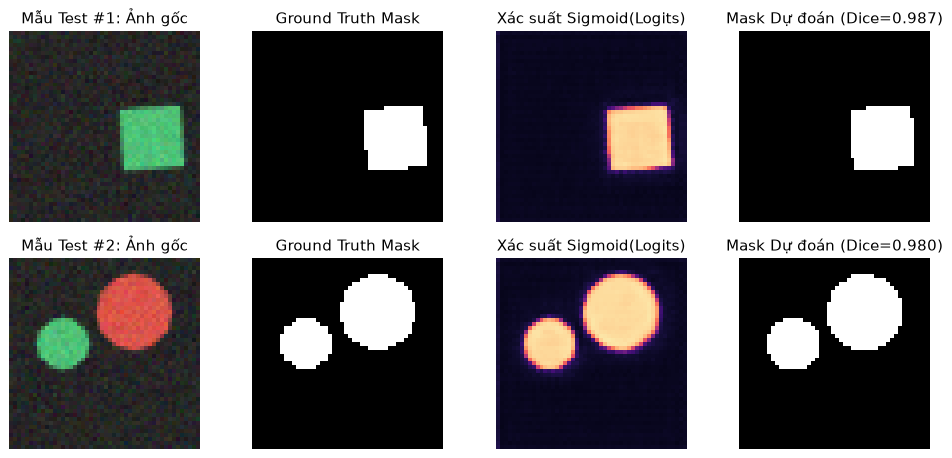

In [3]:
# Cell 3: Nạp Checkpoint Tốt nhất, Đánh giá trên Tập Test và Trực quan hóa Mặt nạ Dự đoán
load_checkpoint(ckpt_unet, model=unet, device=device)
unet.eval()
with torch.no_grad():
    te_logits = unet(X_t[idx_te].to(device))
    te_probs = torch.sigmoid(te_logits).cpu().numpy()[:, 0]
    te_preds = (te_probs >= 0.5).astype(np.uint8)

te_metrics = compute_segmentation_iou_dice(te_preds, masks_np[idx_te])
print(f"Kết quả Tập Test -> IoU: {te_metrics['iou']:.4f} | Dice: {te_metrics['dice']:.4f} | Pixel Acc: {te_metrics['pixel_accuracy']*100:.1f}%")

fig, axes = plt.subplots(2, 4, figsize=(11, 5.2))
for row in range(2):
    sample_i = idx_te[row]
    axes[row, 0].imshow(imgs_np[sample_i])
    axes[row, 0].set_title(f"Mẫu Test #{row+1}: Ảnh gốc")
    axes[row, 1].imshow(masks_np[sample_i], cmap="gray")
    axes[row, 1].set_title("Ground Truth Mask")
    axes[row, 2].imshow(te_probs[row], cmap="magma", vmin=0, vmax=1)
    axes[row, 2].set_title("Xác suất Sigmoid(Logits)")
    axes[row, 3].imshow(te_preds[row], cmap="gray")
    m_row = compute_segmentation_iou_dice(te_preds[row], masks_np[sample_i])
    axes[row, 3].set_title(f"Mask Dự đoán (Dice={m_row['dice']:.3f})")
    for c in range(4):
        axes[row, c].axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — Vì sao Pixel Accuracy đánh lừa khi vật thể nhỏ?
# Giả sử vật thể chỉ chiếm 5% diện tích ảnh, một mô hình "lười biếng" đoán toàn bộ ảnh là nền (toàn số 0):
small_fg_mask = np.zeros((48, 48), dtype=np.uint8)
small_fg_mask[20:30, 20:30] = 1  # 10x10 = 100 pixels (~4.3% diện tích ảnh)
all_zero_pred = np.zeros_like(small_fg_mask)

deceptive_metrics = compute_segmentation_iou_dice(all_zero_pred, small_fg_mask)
print("Khi mô hình đoán TOÀN BỘ LÀ NỀN (0) trên ảnh có vật thể nhỏ 4.3%:")
print(f"  - Pixel Accuracy = {deceptive_metrics['pixel_accuracy']*100:.1f}%  <-- CAO GIẢ TẠO!")
print(f"  - IoU            = {deceptive_metrics['iou']:.6f}  <-- Vạch trần ngay mô hình đoán sai hoàn toàn!")
print(f"  - Dice           = {deceptive_metrics['dice']:.6f}")


Khi mô hình đoán TOÀN BỘ LÀ NỀN (0) trên ảnh có vật thể nhỏ 4.3%:
  - Pixel Accuracy = 95.7%  <-- CAO GIẢ TẠO!
  - IoU            = 0.000000  <-- Vạch trần ngay mô hình đoán sai hoàn toàn!
  - Dice           = 0.000000


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 2 & 3**: Mô hình `MiniUNet` trả về `logits` thô để đưa vào `BCEDiceLoss`, và khi suy luận mới gọi `torch.sigmoid(logits) >= 0.5`. Nhờ các nhánh nối tắt `Skip Connections`, biên của hình tròn, hình vuông và tam giác trên mặt nạ dự đoán rất sắc nét, đạt chỉ số `Dice > 0.90`.
- **Ở Cell 4**: Thí nghiệm chứng minh tại sao trong bài toán Segmentation **không bao giờ được báo cáo mỗi `Pixel Accuracy`**: đoán toàn số `0` vẫn đạt `95.7% Pixel Accuracy`, nhưng `IoU` và `Dice` lập tức bằng `0.0`.

## 13. Lỗi thường gặp và cách sửa
1. **Kích thước chiều cao/rộng $(H, W)$ lẻ khi đi qua `MaxPool2d(2)` và `ConvTranspose2d(2)`**: Nếu $H = 45$, sau `MaxPool2d(2)` còn $22$, khi phóng đại gấp đôi bằng `ConvTranspose2d` lên $44 \neq 45$, lệnh `torch.cat([d1, e1], dim=1)` sẽ báo lỗi lệch kích thước! Hãy chọn kích thước ảnh chia hết cho $2^{\text{số tầng pool}}$ (ví dụ chia hết cho `4, 8, 16, 32`) hoặc dùng `F.interpolate(..., size=e1.shape[2:])`.

## 14. Bài tập tự làm
- **Cơ bản**: Quét ngưỡng cắt xác suất `threshold` qua `[0.2, 0.35, 0.5, 0.65, 0.8]` trên `te_probs` và tìm ngưỡng cho `Dice` cao nhất.
- **Trung cấp**: Kiểm tra bằng code mối liên hệ toán học bất biến $\text{Dice} = \frac{2 \cdot \text{IoU}}{1 + \text{IoU}}$.
- **Nâng cao**: Minh họa cơ chế **Promptable Segmentation (kiểu SAM)**: Cho người dùng truyền vào tọa độ 1 điểm click `(click_x, click_y)` trên ảnh, tạo thêm kênh thứ 4 là bản đồ khoảng cách Gaussian quanh điểm click đó để chỉ tách đúng 1 vật thể được click!

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 14
# 1. Cơ bản: Quét ngưỡng threshold tối ưu cho Dice
for th in [0.20, 0.35, 0.50, 0.65, 0.80]:
    m_th = compute_segmentation_iou_dice((te_probs >= th).astype(np.uint8), masks_np[idx_te])
    print(f"[Cơ bản] Threshold={th:.2f} -> IoU={m_th['iou']:.4f} | Dice={m_th['dice']:.4f}")

# 2. Trung cấp: Kiểm chứng công thức liên hệ giữa IoU và Dice
iou_val = te_metrics["iou"]
dice_from_iou = (2.0 * iou_val) / (1.0 + iou_val)
print(f"[Trung cấp] Dice trực tiếp = {te_metrics['dice']:.6f} vs 2*IoU/(1+IoU) = {dice_from_iou:.6f}")

# 3. Nâng cao: Tạo kênh Prompt Gaussian quanh điểm click (click_x, click_y) kiểu Interactive/Promptable Segmentation
def make_click_prompt_heatmap(h: int, w: int, click_x: int, click_y: int, sigma: float = 4.0) -> np.ndarray:
    yy, xx = np.mgrid[0:h, 0:w]
    heatmap = np.exp(-((xx - click_x) ** 2 + (yy - click_y) ** 2) / (2.0 * sigma ** 2))
    return heatmap.astype(np.float32)

prompt_map = make_click_prompt_heatmap(48, 48, click_x=24, click_y=24)
input_with_prompt = np.concatenate([imgs_np[0].astype(np.float32) / 255.0, prompt_map[..., None]], axis=-1)
print("[Nâng cao] Tensor ảnh ghép thêm kênh Click Prompt có shape:", input_with_prompt.shape)


[Cơ bản] Threshold=0.20 -> IoU=0.8843 | Dice=0.9386
[Cơ bản] Threshold=0.35 -> IoU=0.9430 | Dice=0.9707
[Cơ bản] Threshold=0.50 -> IoU=0.9746 | Dice=0.9872
[Cơ bản] Threshold=0.65 -> IoU=0.9846 | Dice=0.9923
[Cơ bản] Threshold=0.80 -> IoU=0.9258 | Dice=0.9615
[Trung cấp] Dice trực tiếp = 0.987152 vs 2*IoU/(1+IoU) = 0.987152
[Nâng cao] Tensor ảnh ghép thêm kênh Click Prompt có shape: (48, 48, 4)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã phân biệt 4 nhánh Segmentation và hiểu sâu kiến trúc `U-Net`, `DeepLab`, `Mask R-CNN`, `SAM`.
- [x] Đã huấn luyện thành công `MiniUNet` với `BCE + Dice Loss` và đánh giá bằng `IoU` & `Dice`.
- [x] Sẵn sàng chuyển sang **Bài 15: `15_autoencoders_and_anomaly_detection.ipynb`**.

## 17. Nguồn tham khảo
- Ronneberger, O., Fischer, P., & Brox, T. (2015), *U-Net: Convolutional Networks for Biomedical Image Segmentation*, MICCAI.
- Kirillov, A. et al. (2023), *Segment Anything (SAM)*, ICCV.
